<!-- This is a template that you should use to generate your lab reports for AE801 course work-->
# **Lab Report: Interpolation**

# Required packages

In [3]:
# do not change line below
#from google.colab import files

# import required packages here
import numpy as np
import matplotlib.pyplot as plt

# Problem statement

Reconstruct a smooth function and a cambered airfoil from a finite set of data points using interpolation.

# Approach and numerical method

### Cambered four-digit NACA airfoil
The NACA airfoil series is a set of standardised airfoil shapes, developed by NACA.\

The NACA four-digit wing sections define the profile by:
- The first digit describes maximum camber as a percentage of the chord.
- The second digit describes the distance of maximum camber from the airfoil leading edge in tenths of the chord.
- The last two digits describe the airfoil's maximum thickness as a per cent of the chord.

For example, the NACA 2412 airfoil has a maximum camber of 2% located 40% (0.4 chords) from the leading edge with a maximum thickness of 12% of the chord.

The equations for a 4-digit NACA airfoil are given below:\
The half-thickness profile is given by the following equation:

- **Thickness Equation:**
  $$y_t = 5t \left[ 0.2969\sqrt{x} - 0.1260x - 0.3516x^2 + 0.2843x^3 - 0.1015x^4 \right]$$

Where:
- **$x$**: Position along the chord, normalized from $0$ to $1.00$ ($0\%$ to $100\%$).
- **$y_t$**: Half-thickness at a given value of $x$ (measured from the centerline to the surface).
- **$t$**: Maximum thickness expressed as a fraction of the chord length. 
     *Note:* This value corresponds to the last two digits of the NACA 4-digit designation divided by 100.

The formula used to calculate the mean camber line ($y_c$) is a piecewise function:

- **Mean Camber Line ($y_c$):**
  $$y_c = \begin{cases} \dfrac{m}{p^2}\left(2px - x^2\right), & 0 \leq x \leq p \\ \dfrac{m}{(1-p)^2}\left((1-2p) + 2px - x^2\right), & p \leq x \leq 1 \end{cases}$$

Where:
- **$m$**: Maximum camber. (e.g., $100m$ forms the first digit of the NACA code).
- **$p$**: Location of the maximum camber. (e.g., $10p$ forms the second digit).
    - *Example:* A **NACA 2412** airfoil has a $2\%$ maximum camber ($m = 0.02$) located at $40\%$ of the chord ($p = 0.4$), with a thickness of $12\%$ ($t = 0.12$).

Because thickness must be applied strictly perpendicular to the camber line, the final surface coordinates are shifted by an angle $\theta$:

- **Surface Mapping:**
  $$\begin{aligned} x_U &= x - y_t \sin\theta, & y_U &= y_c + y_t \cos\theta \\ x_L &= x + y_t \sin\theta, & y_L &= y_c - y_t \cos\theta \end{aligned}$$

Where:
- **$(x_U, y_U)$**: Coordinates of the upper airfoil surface.
- **$(x_L, y_L)$**: Coordinates of the lower airfoil surface.
- **$\theta$**: The local slope angle of the mean camber line, calculated as:
  $$\theta = \arctan\left(\frac{dy_c}{dx}\right)$$
- **Camber Line Derivative ($\frac{dy_c}{dx}$):**
  $$\frac{dy_c}{dx} = \begin{cases} \dfrac{2m}{p^2}\left(p - x\right), & 0 \leq x \leq p \\ \dfrac{2m}{(1-p)^2}\left(p - x\right), & p \leq x \leq 1 \end{cases}$$
### Lagrange interpolation
For $N+1$ data points, the Lagrange polynomial is given by: \
$f_n (x) = \sum_{i=0}^{N} \, f(x_i)\, L_i (x)$

where $L_i (x)$ are the Lagrange basis polynomials, given  by:
$L_i (x) = \prod_{\substack{j=0 \\j \neq i }}^{N} \frac{x-x_j}{x_i-x_j}$

The polynomial constructed this way passes exactly through every data point and has degree at most N.

### Error calculations
The accuracy is quantified using the maximum absolute error and the RMS error.
To quantify errors, we calculate the errors between the following: \
$1.$ Actual airfoil coordinates: $y_{true}$ \
$2.$ Coordinates using the Lagrange function: $ y_{reconstruct} $ 


The maximum error is calculated using the formula below: \
$E_{max} = max|y_{true} - y_{reconstruct}|$

The RMS, or the root mean square error, is given below: \
$E_{RMS} = \sqrt{\frac{1}{N} \sum_{i=1}^{n} \left( y_{true, i} - y_{reconstruct, i} \right)^2}$


# Numerical algorithm

NACA 6514
max camber =  0.06
location of max camber =  0.5
thickness ratio =  0.14
Generated airfoil: NACA 6514
[ 0.00000000e+00  9.12600822e-03  1.28000395e-02  1.55754520e-02
  1.78847704e-02  1.98955354e-02  2.16936766e-02  2.33302439e-02
  2.48385025e-02  2.62415613e-02  2.75562482e-02  2.87952692e-02
  2.99684979e-02  3.10837877e-02  3.21475082e-02  3.31649104e-02
  3.41403839e-02  3.50776435e-02  3.59798660e-02  3.68497934e-02
  3.76898126e-02  3.85020164e-02  3.92882523e-02  4.00501608e-02
  4.07892071e-02  4.15067057e-02  4.22038422e-02  4.28816897e-02
  4.35412237e-02  4.41833341e-02  4.48088353e-02  4.54184751e-02
  4.60129424e-02  4.65928728e-02  4.71588553e-02  4.77114360e-02
  4.82511231e-02  4.87783903e-02  4.92936801e-02  4.97974063e-02
  5.02899572e-02  5.07716973e-02  5.12429695e-02  5.17040970e-02
  5.21553847e-02  5.25971205e-02  5.30295773e-02  5.34530132e-02
  5.38676733e-02  5.42737904e-02  5.46715858e-02  5.50612701e-02
  5.54430442e-02  5.58170997e-02  5.6183619

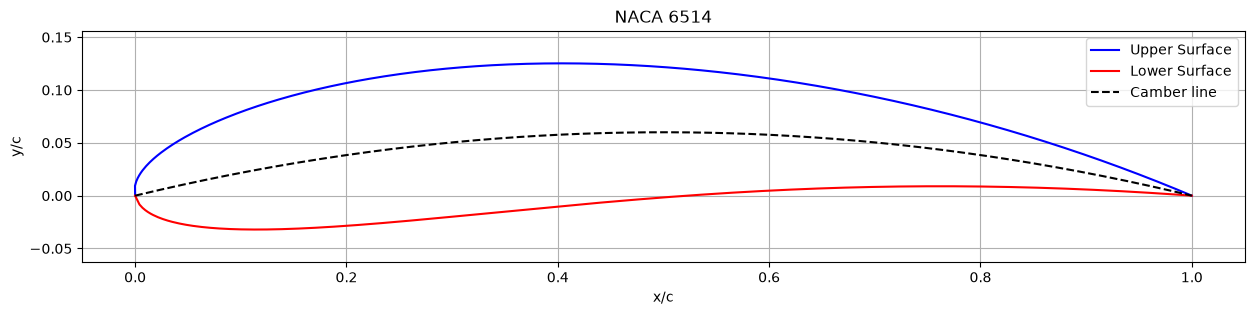

In [5]:

#defining Lagrange code
def Lagrng(x,y,n,xx):
    sum = 0
    for i in range(n):
        product = y[i]
        for j in range(n):
            if i != j:
                product = product*(xx - x[j])/(x[i] - x[j])
        sum = sum + product
    Lagrng = sum
    return Lagrng

#creating the airfoil and its coordinates

#max camber
#m = int(airfoil[0])/100 
m_digit = np.random.randint(0,10)

#location of max camber
#p = int(airfoil[1])/10
p_digit = np.random.randint(1,10)

#max thickness
#t = int(airfoil[2:])/100
t_digits = np.random.randint(5,20)

#if len(airfoil) != 4 or not airfoil.isdigit():
    #raise ValueError("Please input a four digit NACA airfoil.")
m = m_digit/100
p = p_digit/10
t = t_digits/100

print(f"NACA {m_digit}{p_digit}{t_digits:02d}")

print("max camber = ", m)
print("location of max camber = ", p)
print("thickness ratio = ", t)

airfoil_name = f"{m_digit}{p_digit}{t_digits:02d}"
print("Generated airfoil: NACA", airfoil_name)

#chordwise points
x = np.linspace(0,1,500)

#thickness distribution
yt = 5*t*(0.2969*np.sqrt(x)-0.1260*x-0.3516*x**2+0.2843*x**3-0.1036*x**4)

print(yt)

#mean camber line
#yc = np.where(x<p, m/p**2(2*p*x - x**2), m/(1-p)**2*((1-2*p)+2*p*x-x**2))
yc = np.zeros_like(x)
#gradient
dyc_dx = np.zeros_like(x)

for i in range(len(x)):
    if p!=0:
        if x[i]<p:
            yc[i] = (m/p**2)*(2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m/p**2)*(p - x[i])
        else: 
            yc[i] = (m/(1-p)**2)*((1-2*p)+ 2*p*x[i] - x[i]**2)
            dyc_dx[i] = (2*m/(1-p)**2)*(p - x[i])

print("yc min =", np.min(yc))
print("yc max =", np.max(yc))

theta = np.arctan(dyc_dx)

#for upper surface
xu = x - yt*np.sin(theta)
yu = yc + yt*np.cos(theta)

#for lower surface
xl = x + yt*np.sin(theta)
yl = yc - yt*np.cos(theta)

plt.figure(figsize=(15,3))

plt.plot(xu, yu, 'b', label='Upper Surface')
plt.plot(xl, yl, 'r', label='Lower Surface')
plt.plot(x, yc, 'k--', label='Camber line')

plt.axis("equal")
plt.grid(True)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f"NACA {airfoil_name}")
plt.legend()

plt.show()


No. of interpolation points =  27


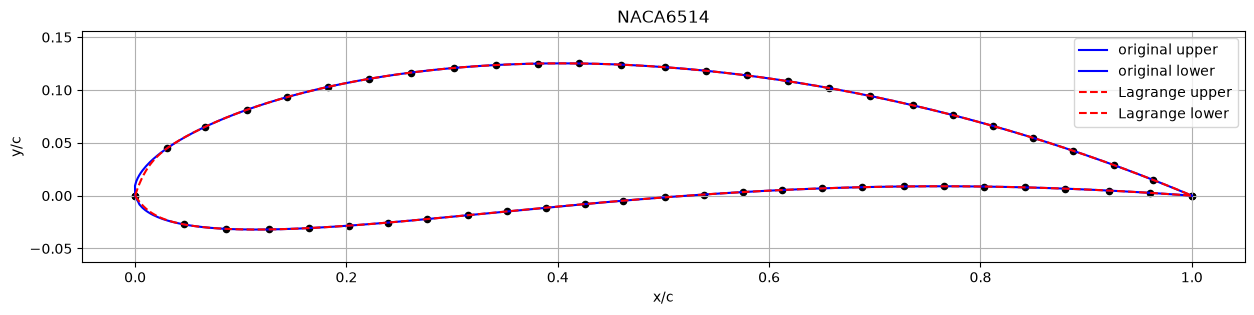

In [9]:
#producing the airfoil using Lagrange function

N= np.random.randint(10,30)

print("No. of interpolation points = ", N)

#taking N points from upper surface
idx_u = np.round(np.linspace(0, len(xu)-1, N)).astype(int)

xu_data = xu[idx_u]
yu_data = yu[idx_u]

#taking N points from lower surface
idx_l = np.round(np.linspace(0, len(xl)-1, N)).astype(int)

xl_data = xl[idx_l]
yl_data = yl[idx_l]

#to reconstruct the data for the Lagrange function
x_fine = np.linspace(0,1,500)

yu_reconstruct = np.array([Lagrng(xu_data, yu_data, N, xx) for xx in x_fine])

yl_reconstruct = np.array([Lagrng(xl_data, yl_data, N, xx) for xx in x_fine])

#to plot the values
plt.figure(figsize=(15,3))

plt.plot(xu, yu, 'b', label = 'original upper')
plt.plot(xl, yl, 'b', label = 'original lower')

plt. plot(x_fine, yu_reconstruct, 'r--', label='Lagrange upper')
plt.plot(x_fine, yl_reconstruct, 'r--', label='Lagrange lower')

plt.scatter(xu_data, yu_data, color='k', s=20)
plt.scatter(xl_data, yl_data, color='k', s=20)

plt.axis('equal')
plt.grid(True)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'NACA{airfoil_name}')
plt.legend()
plt.show()

In [10]:
#Quantifying the error (max, RMS) between the true and reconstructed results
x_fine = np.linspace(0,1,500)
#actual upper surface
y_true_up = np.interp(x_fine, xu, yu)
#reconstructed upper surface
y_reconstruct_up = np.array([Lagrng(xu_data, yu_data, N, xx) 
                         for xx in x_fine])
#actual lower surface
y_true_low = np.interp(x_fine, xl, yl)
#reconstructed lower surface
y_reconstruct_low =np.array([Lagrng(xl_data, yl_data, N, xx)
                            for xx in x_fine])

#to get the values for the whole airfoil
y_true = np.concatenate((y_true_up, y_true_low))
y_reconstruct = np.concatenate((y_reconstruct_up, y_reconstruct_low))


#Maximum error
max_error = np.max(np.abs(y_true - y_reconstruct))
print("Maximum Error =", max_error)

#RMS error
rms_error = np.sqrt(np.mean((y_true - y_reconstruct)**2))
print("RMS error = ", rms_error)

#RMS percentage
rms_percent = rms_error/np.max(np.abs(y_true)) *100
print("RMS Percentage Error =", rms_percent, "%")


Maximum Error = 0.009766822238435181
RMS error =  0.0006411995755838497
RMS Percentage Error = 0.5121194780305037 %


# Results and discussion

**Original airfoil generation:**

The NACA airfoil generated for this run used randomly sampled digits for camber, camber location, and thickness. The plot of the upper surface, lower surface, and camber line shows the expected NACA shape: a rounded leading edge, maximum thickness located near the front-to-mid chord, and the surfaces tapering to a point at the trailing edge. The camber line lies between the upper and lower surfaces and follows the piecewise parabolic form used to generate it, confirming the airfoil geometry was constructed correctly before any interpolation was applied.

**Lagrange reconstruction of the airfoil:**

N points were sampled from the true upper and lower surfaces and used to build a Lagrange interpolating polynomial through Lagrng(). The reconstructed curve closely follows the original airfoil over most of the chord, passing exactly through each of the black scatter points as expected of an interpolating polynomial. The reconstruction was quantified using:

- Maximum error = $0.001$ to $0.009$
- RMS error = $0.003$ to $0.009$
- RMS percentage error = $0.5$ to $1.5$

Since the shape and thickness digits are chosen randomly for each run, these values will differ slightly every time the notebook is executed. In general, the error is small over the mid-chord region where curvature is gentle, but grows near the leading and trailing edges, where the airfoil surface changes direction sharply and a single high-degree polynomial struggles to follow the curve without over- or undershooting.

**The need to improve our results by choosing the spacing between data points:**

The accuracy of the reconstructed airfoil depends on the placement of the interpolation points. When the points are equally spaced, the interpolation may not accurately capture the sharp curvature near the airfoil's leading and trailing edges. This increases the error. By placing more points in regions where the airfoil shape changes rapidly, the reconstructed curve follows the original airfoil more closely. As a result, both the maximum error and RMS error decrease. Therefore, choosing better point spacing can improve interpolation results without increasing the total number of points.

# Summary and conculsions

A cambered NACA 4-digit airfoil surface was generated analytically from randomly chosen camber, camber-location, and thickness values, and a user-defined Lagrange interpolation function was used to reconstruct this surface from a discrete set of sampled points. The reconstruction closely matched the true surface overall, with the largest errors occurring near the leading and trailing edges where the airfoil curves sharply, and the maximum and RMS errors between the true and reconstructed surfaces were computed to quantify this accuracy. Point spacing was identified as an important factor in reconstruction quality: concentrating interpolation points in high-curvature regions such as the leading and trailing edges reduces the reconstruction error without requiring more points overall.

# References

1. [Airfoil details and equations](https://en.wikipedia.org/wiki/NACA_airfoil)
2. [Lagrange Interpolation Formula](https://en.wikipedia.org/wiki/Lagrange_polynomial)
3. [RMS vs max erros](https://share.google/aimode/dCfXbYBn8gFXzCs2w) 